<a href="https://colab.research.google.com/github/brhan29/makemore/blob/main/makemore_p5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
!wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
words = open('names.txt', 'r').read().splitlines()

--2026-10-11 17:18:27--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt’

names.txt           100%[===================>] 222.80K  --.-KB/s    in 0.01s   

2026-10-11 17:18:27 (19.0 MB/s) - ‘names.txt’ saved [228145/228145]



In [13]:
chars = sorted(set(''.join(words)))
stoi = {s:(i+1) for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [19]:
import random
random.seed(42)
random.shuffle(words)

block_size = 8

def build_dataset(words):
  X = []; Y = []
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      X.append(context)
      Y.append(stoi[ch])
      context = context[1:] + [stoi[ch]]
  return torch.tensor(X), torch.tensor(Y)

n1 = int(len(words) * 0.8)
n2 = int(len(words) * 0.9)
Xtr, Ytr = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [26]:
# Implement torch.nn classes

#-------------------------------------------------

class Linear:

  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out)) / fan_in ** 0.5
    self.bias = torch.zeros(fan_out) if bias else None

  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias != None:
      self.out += self.bias
    return self.out

  def parameters(self):
    return [self.weight] + [self.bias] if self.bias != None else []

#-------------------------------------------------

# We have to modify batchnorm here to take (Batch_size) x (Length) x (Number of features per pixel) and normalize accross features
class BatchNorm1d:

  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)

  def __call__(self, x):
    if self.training:
      if x.ndim == 2:
        dim = 0
      if x.ndim == 3:
        dim = (0,1)
      xmean = x.mean(dim, keepdims=True)
      xvar = x.var(dim, keepdims=True)
    else:
      xmean = self.running_mean
      xvar = self.running_var

    # For 3D case xhat is a BxLxN tensor, while xmean xvar are 1x1xN tensors --> Broadcasts properly
    # Also if multiplying, say a 3D tensor BxLxN by a 2D tensor NxK, matrix multiplication works with just the last dim of the 3D tensor!
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
    self.out = xhat * self.gamma + self.beta

    if self.training:
      with torch.no_grad():
        # After the first iteration self.running_mean and var change shape to (1,1,N)!
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]

#-------------------------------------------------

class Tanh:

  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out

  def parameters(self):
    return []

#-------------------------------------------------

# We make a module for the initial feature embedding to make everything neater
class Embedding:

  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))

  def __call__(self, x):
    self.out = self.weight[x]
    return self.out

  def parameters(self):
    return [self.weight]

#-------------------------------------------------

# We also make a class for reshaping tensors (concatenating adjacent pixels)
class FlattenConsecutive:

  def __init__(self, n):
    self.n = n

  def __call__(self, x):
    B, T, C = x.shape
    x = x.view(B, T//self.n, C * self.n)
    if (x.shape[1] == 1):
      x = x.squeeze(1)
    self.out = x
    return self.out

  def parameters(self):
    return []

#-------------------------------------------------

# We also implement the sequential container from torch
class Sequential:

  def __init__(self, layers):
    self.layers = layers

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [27]:
torch.manual_seed(42);

In [34]:
# For similar parameter count to original MLP
n_embd = 24
n_hidden = 128
vocab_size = 27

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

with torch.no_grad():
  model.layers[-1].weight *= 0.1

parameters = model.parameters()
for p in parameters:
  p.requires_grad = True

In [35]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  ix = torch.randint(Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix]

  logits = model(Xb)
  loss = F.cross_entropy(logits, Yb)
  for p in parameters:
    p.grad = None
  loss.backward()

  lr = 0.1 if i < 150000 else 0.01
  for p in parameters:
    p.data -= lr * p.grad

  if i % 10000 == 0:
    print(f'{i}/200000, loss is {loss}')
  lossi.append(loss.log10().item())

0/200000, loss is 3.3073744773864746
10000/200000, loss is 2.5985987186431885
20000/200000, loss is 1.9796180725097656
30000/200000, loss is 1.9413505792617798
40000/200000, loss is 2.433068037033081
50000/200000, loss is 1.9329297542572021
60000/200000, loss is 2.0196030139923096
70000/200000, loss is 2.4047746658325195
80000/200000, loss is 2.119962692260742
90000/200000, loss is 2.268800735473633
100000/200000, loss is 2.252476930618286
110000/200000, loss is 1.846078634262085
120000/200000, loss is 2.478473424911499
130000/200000, loss is 2.281466245651245
140000/200000, loss is 2.043055295944214
150000/200000, loss is 1.8625507354736328
160000/200000, loss is 2.1885735988616943
170000/200000, loss is 2.3610482215881348
180000/200000, loss is 1.9676661491394043
190000/200000, loss is 2.259199619293213


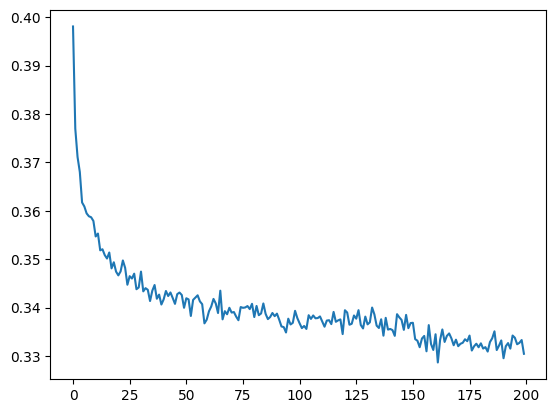

In [36]:
plt.plot(torch.tensor(lossi).view(-1,1000).mean(1))

In [37]:
for layer in model.layers:
  layer.training = False

In [41]:
@torch.no_grad()
def compute_loss(X,Y):
  logits = model(X)
  loss = F.cross_entropy(logits,Y)
  return loss.item()

print(f'Training loss is {compute_loss(Xtr,Ytr)}')
print(f'Val loss is {compute_loss(Xval,Yval)}')
print(f'Test loss is {compute_loss(Xte,Yte)}')

Training loss is 2.1235594749450684
Val loss is 2.144078016281128
Test loss is 2.1483867168426514


In [43]:
# Generate samples
for i in range(20):
  out = []
  context = [0] * block_size
  while True:
    logits = model(torch.tensor([context]))
    probs = F.softmax(logits)
    ix = torch.multinomial(probs, num_samples=1).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
  print(''.join(itos[ix] for ix in out))

/tmp/ipykernel_1816/2862281959.py:7: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  probs = F.softmax(logits)


phirer.
tayleh.
bellynn.
finta.
mylea.
aalya.
beneltna.
cybira.
rolojen.
fhuda.
dazelie.
andrawibe.
andris.
elisia.
amanla.
rashain.
leee.
mayven.
amlin.
jahapen.
